# 3. KD-Tree

A **KD-tree** is a binary tree that recursively splits the data along one coordinate axis at a time, usually at the median. Each node therefore corresponds to an axis-aligned box of space.

To answer a query, the tree:

1. descends to the leaf containing the query and collects candidate neighbours,
2. backtracks, **skipping (pruning) any box that is farther away than the current k-th best neighbour**.

In low dimensions most boxes can be pruned and a query takes roughly $O(\log n)$ time. The search is still **exact**, so recall should be 1.0.

The question for this notebook: **does the KD-tree beat brute force on our 384-dimensional embeddings?** We use `scipy.spatial.KDTree`.

In [9]:
# Load the embeddings, queries, ground truth and the brute-force baseline.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import KDTree
from evaluation import evaluate_search, measure_build_time

DATA_DIR = Path("wikipedia_nn_data")
K = 10

X = np.load(DATA_DIR / "embeddings.npy")
Q = np.load(DATA_DIR / "queries.npy")
ground_truth = np.load(DATA_DIR / "ground_truth.npy")

baseline_results = pd.read_csv(
    DATA_DIR / "baseline_results.csv"
)

print("Database shape:", X.shape)
print("Query shape:", Q.shape)
print("Ground truth shape:", ground_truth.shape)

Database shape: (50000, 384)
Query shape: (500, 384)
Ground truth shape: (500, 10)


## Build the tree

Building the tree is a one-time cost, $O(n \log n)$, paid before any queries are answered.

In [10]:
# Build the KD-tree over the 50,000 database vectors (median of 3 builds).
tree, kd_build_time = measure_build_time(
    lambda: KDTree(X),
    repeats=3
)

print(f"KDTree build time: {kd_build_time:.4f} s")

KDTree build time: 0.2302 s


## Search

In [3]:
def kd_tree_search(q, k=10):
    """Exact k-NN using the KD-tree. eps=0 means no approximation and
    p=2 means Euclidean distance, matching the brute-force ground truth."""
    distances, indices = tree.query(
        q,
        k=k,
        eps=0,
        p=2
    )

    return indices

## Evaluate

The KD-tree is measured with the same `evaluate_search` function as brute force, so the two numbers are directly comparable.

In [4]:
# Measure recall@10 and average query time against the ground truth.
kd_results = evaluate_search(
    search_fn=kd_tree_search,
    Q=Q,
    ground_truth=ground_truth,
    k=K,
    repeats=3
)

print(f"Recall@10: {kd_results['recall']:.4f}")
print(f"Query time: {kd_results['query_time_ms']:.4f} ms")
print(f"Build time: {kd_build_time:.4f} s")

Recall@10: 1.0000
Query time: 42.3201 ms
Build time: 0.4523 s


## Compare with brute force

In [5]:
# Combine the KD-tree result with the brute-force baseline in one table.
kd_row = pd.DataFrame([
    {
        "algorithm": "KDTree",
        "n": X.shape[0],
        "dimension": X.shape[1],
        "k": K,
        "recall_at_10": kd_results["recall"],
        "query_time_ms": kd_results["query_time_ms"],
        "build_time_s": kd_build_time
    }
])

results = pd.concat(
    [baseline_results, kd_row],
    ignore_index=True
)

results

,algorithm,n,dimension,k,recall_at_10,query_time_ms,build_time_s
0,Brute force,50000,384,10,1.0,34.071585,0.000000
1,KDTree,50000,384,10,1.0,42.320064,0.452316


In [6]:
# Save the combined results.
results.to_csv(
    DATA_DIR / "exact_search_results.csv",
    index=False
)

## Query time comparison

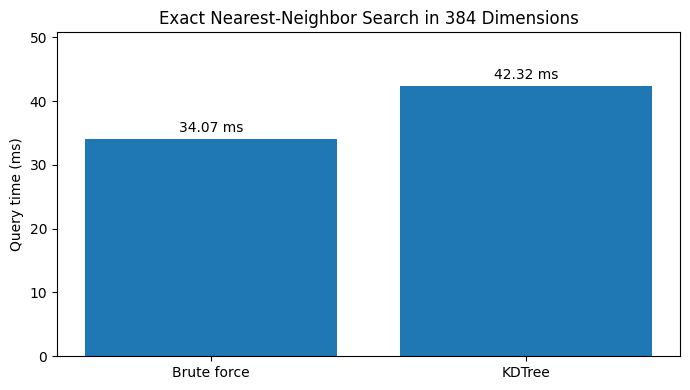

In [7]:
# Bar chart comparing average query time.
plt.figure(figsize=(7, 4))

bars = plt.bar(
    results["algorithm"],
    results["query_time_ms"]
)

plt.bar_label(bars, fmt="%.2f ms", padding=3)

plt.ylabel("Query time (ms)")
plt.title("Exact Nearest-Neighbor Search in 384 Dimensions")
plt.ylim(0, results["query_time_ms"].max() * 1.2)

plt.tight_layout()
plt.show()

In [8]:
# Speedup > 1 means the KD-tree is faster than brute force; < 1 means slower.
brute_time = baseline_results["query_time_ms"].iloc[0]
kd_time = kd_results["query_time_ms"]

speedup = brute_time / kd_time

print(f"KDTree speedup: {speedup:.3f}x")

KDTree speedup: 0.805x


## Results and discussion

| | Brute force | KD-tree |
|---|---|---|
| Recall@10 | 1.0 | 1.0 |
| Query time | 34.1 ms | 42.3 ms |
| Build time | 0 s | 0.45 s |

The KD-tree returns the correct neighbours (recall 1.0), but at 384 dimensions it is **slower than brute force** (speedup ≈ 0.8×), and it also costs extra time to build.

**Why?** This is the *curse of dimensionality*:

* **Too few splits.** A balanced tree on $n = 50{,}000$ points has only about $\log_2 50{,}000 \approx 16$ levels, so any root-to-leaf path splits on at most ~16 of the 384 coordinates. The boxes stay huge in all the other directions.
* **Distances concentrate.** In high dimensions the distance to the nearest and to the farthest points become similar, so the query's distance to almost every box is smaller than its current k-th best distance. Very little can be pruned.
* **Overhead.** The tree ends up visiting most of the data anyway, plus the cost of traversing nodes, which makes it slower than one vectorised brute-force pass.

The next notebook tests this explanation directly by measuring both methods as the number of dimensions grows.

*Note: timings vary by a few milliseconds between runs; notebook 04 measures the 384-dimensional case again and gets slightly different numbers.*